
# GenMol AI: Generative Molecular Design and Interactive Virtual Screening

## Project Overview

GenMol AI is an educational research prototype exploring how generative artificial intelligence can produce candidate molecular structures and how computational chemistry tools can evaluate those candidates.

The project combines:
- Molecular dataset exploration and preparation
- AI-based molecular generation
- Chemical validity and molecular property analysis
- Protein–ligand docking against a selected biological target
- Interactive 2D and 3D molecular visualization
- Candidate comparison through an interactive research interface

## Research Objective

To investigate whether a generative model can produce chemically valid molecular candidates and explore how those candidates perform in a computational screening experiment against a known protein target.

## Scientific Scope

Generated molecules and docking scores are computational research outputs. Chemical validity, predicted binding, and drug-likeness do not establish biological activity, safety, or therapeutic effectiveness.

## Technology Stack

Python, PyTorch, RDKit, AutoDock Vina, Gradio, and 3Dmol.js.

## Reproducibility

Experiments will use documented dataset sources, fixed random seeds where applicable, explicit evaluation metrics, and saved results so that the workflow can be inspected and repeated.


In [ ]:


import sys
import platform
import os
import random

print(f"Python version : {sys.version.split()[0]}")

print(f"Operating system: {platform.system()} {platform.release()}")

try:
    import torch

    print(f"PyTorch version: {torch.__version__}")
    print(f"CUDA available : {torch.cuda.is_available()}")

    if torch.cuda.is_available():
        print(f"GPU device     : {torch.cuda.get_device_name(0)}")
    else:
        print("GPU device     : Not currently available")

except ImportError:
    print("PyTorch         : Not installed yet")

PROJECT_DIR = "/content/genmol_ai"

os.makedirs(PROJECT_DIR, exist_ok=True)

print(f"Project directory: {PROJECT_DIR}")
print("\nEnvironment audit complete.")


Python version : 3.13.16
Operating system: Linux 6.6.159+
PyTorch version: 2.11.0+cu130
CUDA available : True
GPU device     : Tesla T4
Project directory: /content/genmol_ai

Environment audit complete.



## Dataset Selection and Acquisition

We use a ZINC-derived dataset of approximately 250,000 drug-like molecular structures represented as SMILES strings.

SMILES provides a compact textual representation of molecular connectivity, making it suitable for sequence-based generative models.

The dataset will be inspected for its schema, missing values, duplicate entries, and molecular string lengths before it is used for training.

The EGFR protein structure (PDB: 1M17) and its crystallographic reference ligand will be used later to establish and validate the virtual-screening workflow. The training dataset is not assumed to contain EGFR-specific active compounds.


In [ ]:

import os
import random
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = "/content/genmol_ai"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(PROJECT_DIR, "figures")

for directory in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    os.makedirs(directory, exist_ok=True)

DATASET_URL = (
    "https://raw.githubusercontent.com/"
    "aspuru-guzik-group/chemical_vae/master/"
    "models/zinc_properties/250k_rndm_zinc_drugs_clean_3.csv"
)

DATASET_PATH = os.path.join(DATA_DIR, "zinc_250k.csv")

df = pd.read_csv(DATASET_URL)
df.to_csv(DATASET_PATH, index=False)

if "smiles" not in df.columns:
    raise ValueError(f"Expected a 'smiles' column. Found: {df.columns.tolist()}")

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Saved to: {DATASET_PATH}")
print(f"Columns: {df.columns.tolist()}")

display(df.head())


Dataset shape: 249,455 rows × 4 columns
Saved to: /content/genmol_ai/data/zinc_250k.csv
Columns: ['smiles', 'logP', 'qed', 'SAS']


,smiles,logP,qed,SAS
0,CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1\n,5.05060,0.702012,2.084095
1,C[C@@H]1CC(Nc2cncc(-c3nncn3C)c2)C[C@@H](C)C1\n,3.11370,0.928975,3.432004
2,N#Cc1ccc(-c2ccc(O[C@@H](C(=O)N3CCCC3)c3ccccc3)...,4.96778,0.599682,2.470633
3,CCOC(=O)[C@@H]1CCCN(C(=O)c2nc(-c3ccc(C)cc3)n3c...,4.00022,0.690944,2.822753
4,N#CC1=C(SCC(=O)Nc2cccc(Cl)c2)N=C([O-])[C@H](C#...,3.60956,0.789027,4.035182



## Dataset Exploration and Quality Assessment

Before model training, we examine the dataset's completeness, duplicate molecular strings, molecular string lengths, and supplied property distributions.

The analysis helps identify data-quality issues and understand the range and relationships of the dataset's precomputed properties. These properties are useful for exploratory analysis but do not establish biological activity or clinical suitability.

The visualizations will also serve as baseline research figures for the final presentation.


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")

df_explore = df.copy()
df_explore["smiles"] = df_explore["smiles"].astype("string").str.strip()

property_columns = ["logP", "qed", "SAS"]
for column in property_columns:
    df_explore[column] = pd.to_numeric(df_explore[column], errors="coerce")

df_explore = df_explore.replace([np.inf, -np.inf], np.nan)

quality_summary = pd.DataFrame({
    "Metric": [
        "Total records",
        "Missing SMILES",
        "Empty SMILES",
        "Duplicate SMILES",
        "Missing logP",
        "Missing QED",
        "Missing SAS",
    ],
    "Count": [
        len(df_explore),
        int(df_explore["smiles"].isna().sum()),
        int(df_explore["smiles"].fillna("").eq("").sum()),
        int(df_explore["smiles"].dropna().duplicated().sum()),
        int(df_explore["logP"].isna().sum()),
        int(df_explore["qed"].isna().sum()),
        int(df_explore["SAS"].isna().sum()),
    ],
})

display(quality_summary)

display(
    df_explore[property_columns]
    .describe()
    .round(3)
    .rename_axis("Statistic")
)

print(
    "Unique SMILES:",
    f"{df_explore['smiles'].nunique():,}"
)


,Metric,Count
0,Total records,249455
1,Missing SMILES,0
2,Empty SMILES,0
3,Duplicate SMILES,0
4,Missing logP,0
5,Missing QED,0
6,Missing SAS,0


,logP,qed,SAS
Statistic,,,
count,249455.000,249455.000,249455.000
mean,2.457,0.728,3.053
std,1.434,0.140,0.835
min,-6.876,0.112,1.133
25%,1.575,0.646,2.417
50%,2.606,0.760,2.893
75%,3.487,0.836,3.546
max,8.252,0.948,7.289


Unique SMILES: 249,455


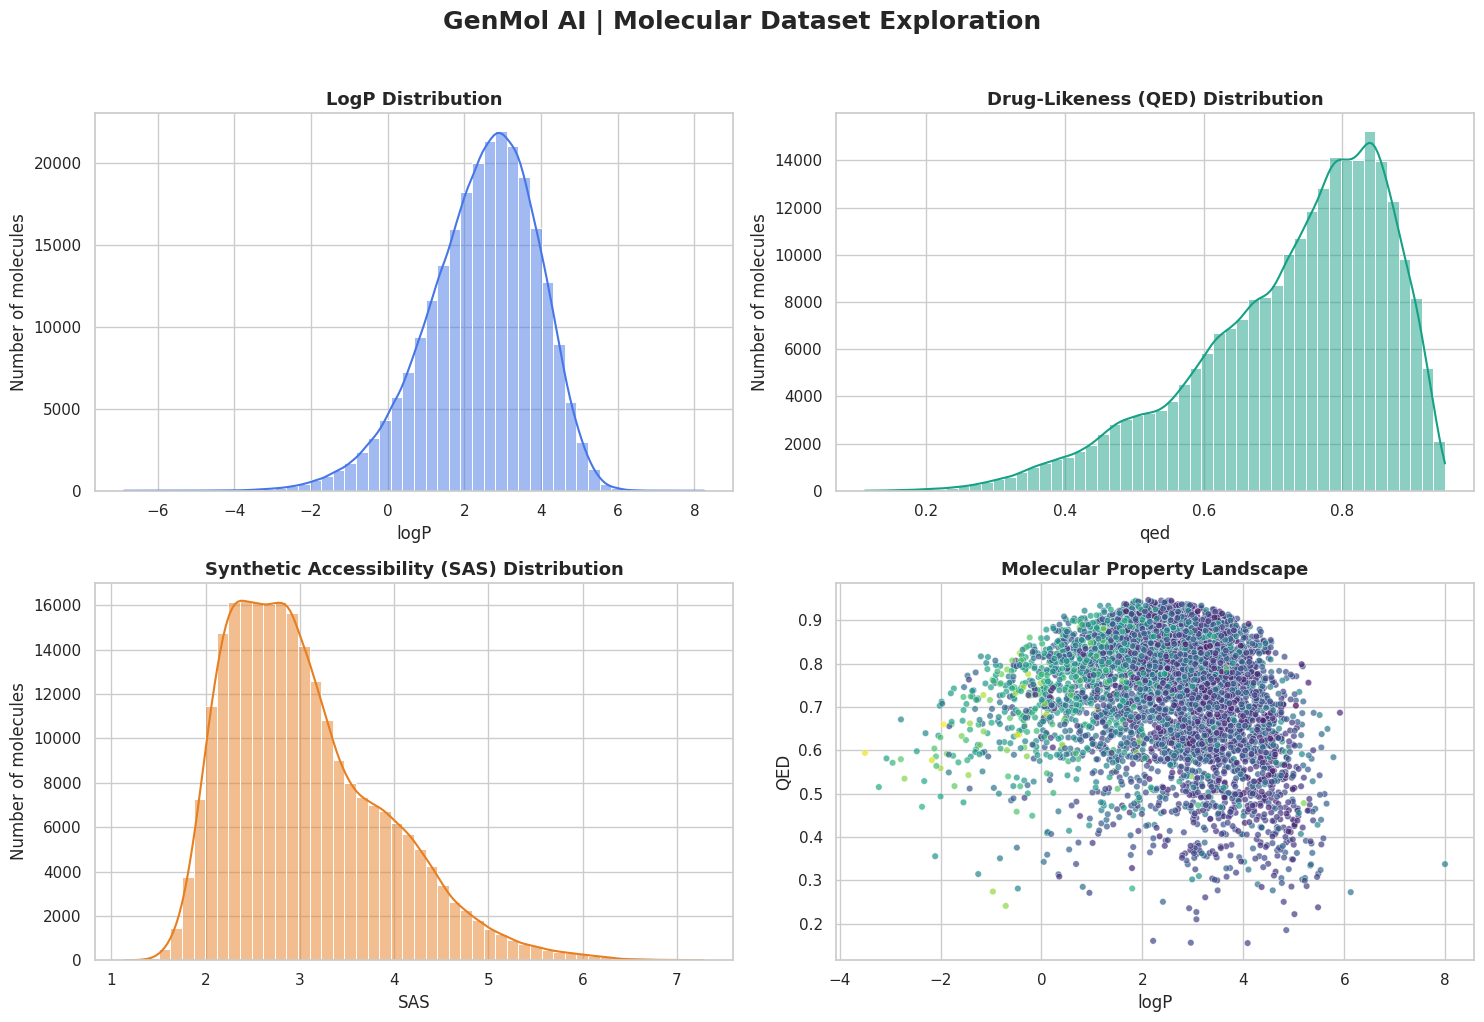

Figure saved to: /content/genmol_ai/figures/dataset_exploration.png


In [ ]:

plot_df = df_explore.dropna(subset=property_columns).copy()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

properties = [
    ("logP", "LogP Distribution", "#4776E6"),
    ("qed", "Drug-Likeness (QED) Distribution", "#16A085"),
    ("SAS", "Synthetic Accessibility (SAS) Distribution", "#E67E22"),
]

for ax, (column, title, color) in zip(axes.flat[:3], properties):
    sns.histplot(
        data=plot_df,
        x=column,
        bins=50,
        kde=True,
        color=color,
        ax=ax
    )
    ax.set_title(title, fontsize=13, weight="bold")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of molecules")

scatter_data = plot_df.sample(
    n=min(5000, len(plot_df)),
    random_state=SEED
)

sns.scatterplot(
    data=scatter_data,
    x="logP",
    y="qed",
    hue="SAS",
    palette="viridis",
    alpha=0.7,
    s=22,
    ax=axes.flat[3],
    legend=False
)

axes.flat[3].set_title(
    "Molecular Property Landscape",
    fontsize=13,
    weight="bold"
)
axes.flat[3].set_xlabel("logP")
axes.flat[3].set_ylabel("QED")

fig.suptitle(
    "GenMol AI | Molecular Dataset Exploration",
    fontsize=18,
    weight="bold",
    y=1.02
)
plt.tight_layout()

figure_path = os.path.join(
    FIGURES_DIR,
    "dataset_exploration.png"
)
fig.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {figure_path}")


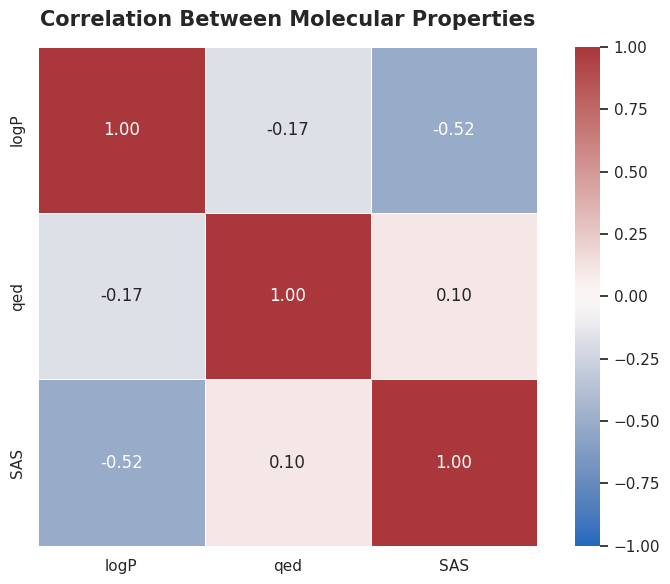

Figure saved to: /content/genmol_ai/figures/property_correlation.png


In [ ]:

correlation = plot_df[property_columns].corr()

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax
)

ax.set_title(
    "Correlation Between Molecular Properties",
    fontsize=15,
    weight="bold",
    pad=15
)

plt.tight_layout()

figure_path = os.path.join(
    FIGURES_DIR,
    "property_correlation.png"
)
fig.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {figure_path}")



## Molecular Validation and Structure Representation

RDKit will convert molecular SMILES strings into molecular graph representations. We will use it to validate chemical syntax, canonicalize structures, calculate molecular descriptors, and render molecular diagrams.

Canonicalization helps identify different SMILES strings that represent the same molecular structure. It does not establish biological activity or guarantee that a molecule can be synthesized.


In [ ]:

%pip install -q rdkit


In [ ]:

from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, Draw, rdMolDescriptors
from IPython.display import display

print("RDKit version:", __import__("rdkit").__version__)
print("Chemical structure tools loaded successfully.")


RDKit version: 2026.09.1
Chemical structure tools loaded successfully.


In [ ]:

validation_df = df_explore[["smiles", "logP", "qed", "SAS"]].copy()

validation_df["mol"] = validation_df["smiles"].map(
    lambda value: Chem.MolFromSmiles(str(value))
    if pd.notna(value) and str(value).strip()
    else None
)

validation_df["is_valid"] = validation_df["mol"].notna()

validation_df["canonical_smiles"] = validation_df["mol"].map(
    lambda mol: Chem.MolToSmiles(mol, canonical=True)
    if mol is not None
    else None
)

valid_df = validation_df.loc[
    validation_df["is_valid"]
].copy()

invalid_df = validation_df.loc[
    ~validation_df["is_valid"]
].copy()

valid_df = valid_df.drop_duplicates(
    subset="canonical_smiles"
).reset_index(drop=True)

print(f"Input records: {len(validation_df):,}")
print(f"Invalid records: {len(invalid_df):,}")
print(f"Unique valid structures: {len(valid_df):,}")
print(
    f"Validity rate: "
    f"{validation_df['is_valid'].mean() * 100:.2f}%"
)


Input records: 249,455
Invalid records: 0
Unique valid structures: 249,455
Validity rate: 100.00%


In [ ]:

valid_df["molecular_weight"] = valid_df["mol"].map(
    Descriptors.MolWt
)
valid_df["calculated_logP"] = valid_df["mol"].map(
    Descriptors.MolLogP
)
valid_df["h_bond_donors"] = valid_df["mol"].map(
    rdMolDescriptors.CalcNumHBD
)
valid_df["h_bond_acceptors"] = valid_df["mol"].map(
    rdMolDescriptors.CalcNumHBA
)
valid_df["tpsa"] = valid_df["mol"].map(
    rdMolDescriptors.CalcTPSA
)
valid_df["rotatable_bonds"] = valid_df["mol"].map(
    rdMolDescriptors.CalcNumRotatableBonds
)
valid_df["heavy_atoms"] = valid_df["mol"].map(
    rdMolDescriptors.CalcNumHeavyAtoms
)

descriptor_columns = [
    "molecular_weight",
    "calculated_logP",
    "h_bond_donors",
    "h_bond_acceptors",
    "tpsa",
    "rotatable_bonds",
    "heavy_atoms",
]

display(valid_df[descriptor_columns].describe().round(2))

descriptor_path = os.path.join(
    RESULTS_DIR,
    "validated_molecular_descriptors.csv"
)

valid_df.drop(columns=["mol"]).to_csv(
    descriptor_path,
    index=False
)

print(f"Descriptor results saved to: {descriptor_path}")


,molecular_weight,calculated_logP,h_bond_donors,h_bond_acceptors,tpsa,rotatable_bonds,heavy_atoms
count,249455.00,249455.00,249455.00,249455.00,249455.00,249455.00,249455.00
mean,332.14,2.46,1.24,3.71,64.82,4.56,23.15
std,61.94,1.43,0.88,1.53,22.93,1.55,4.51
min,150.12,-6.88,0.00,0.00,0.00,0.00,6.00
25%,290.45,1.57,1.00,3.00,49.31,3.00,20.00
50%,333.82,2.61,1.00,4.00,64.11,5.00,23.00
75%,368.46,3.49,2.00,5.00,79.71,6.00,26.00
max,500.00,8.25,6.00,11.00,149.70,11.00,38.00


Descriptor results saved to: /content/genmol_ai/results/validated_molecular_descriptors.csv


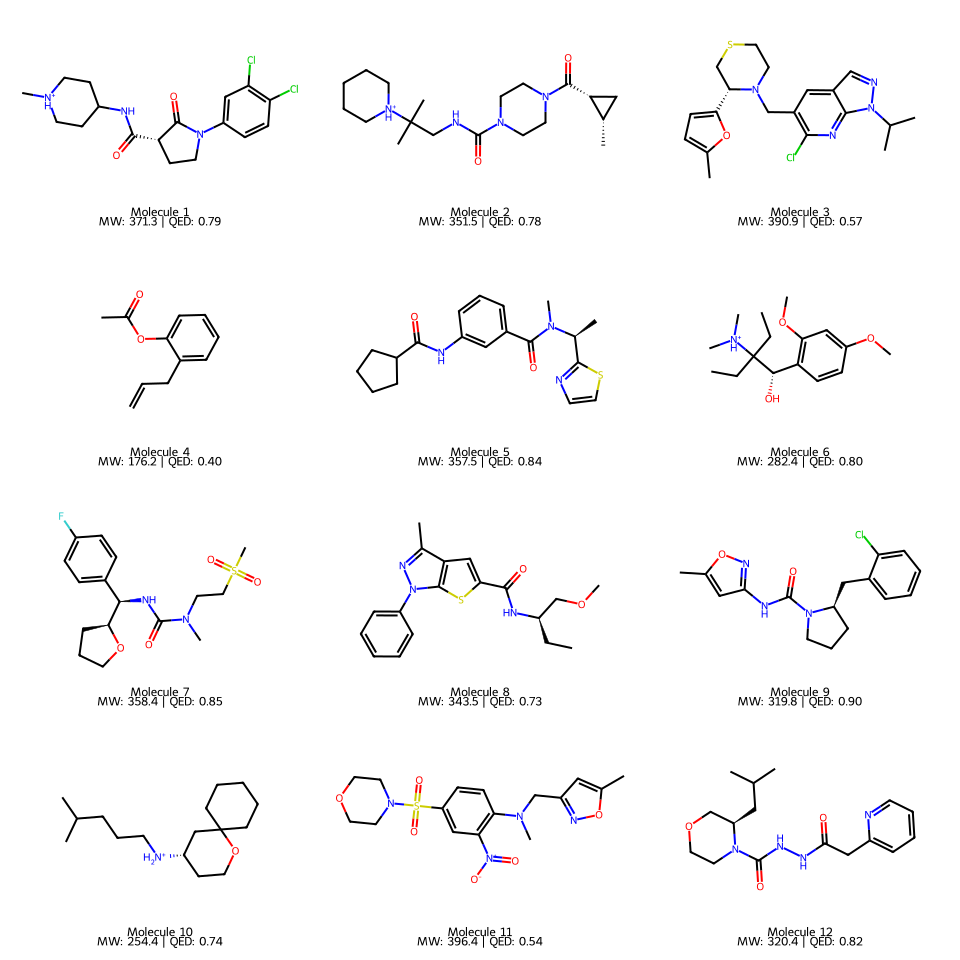

In [ ]:

gallery_df = valid_df.sample(
    n=min(12, len(valid_df)),
    random_state=SEED
).reset_index(drop=True)

molecules = gallery_df["mol"].tolist()
legends = [
    f"Molecule {i + 1}\n"
    f"MW: {gallery_df.loc[i, 'molecular_weight']:.1f} | "
    f"QED: {gallery_df.loc[i, 'qed']:.2f}"
    for i in range(len(gallery_df))
]

molecule_grid = Draw.MolsToGridImage(
    molecules,
    molsPerRow=3,
    subImgSize=(320, 240),
    legends=legends,
    useSVG=True
)

display(molecule_grid)



## Molecular Tokenization and Sequence Preparation

Molecular SMILES strings will be encoded as sequences of character IDs for training a recurrent neural network. Special tokens mark the beginning and end of a sequence, while padding allows sequences of different lengths to be processed in batches.

We will create a reproducible training subset, limit sequence length to control computational cost, and separate training and validation data before model fitting.


In [ ]:

import torch
from torch.utils.data import Dataset, DataLoader, random_split
from torch.nn.utils.rnn import pad_sequence

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Training device:", DEVICE)


PyTorch version: 2.11.0+cu130
Training device: cuda


In [ ]:

smiles_list = (
    valid_df["canonical_smiles"]
    .dropna()
    .astype(str)
    .loc[lambda values: values.str.len() > 0]
    .tolist()
)

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"
START_TOKEN = "<START>"
END_TOKEN = "<END>"

special_tokens = [
    PAD_TOKEN,
    UNK_TOKEN,
    START_TOKEN,
    END_TOKEN,
]

vocabulary = sorted(
    set("".join(smiles_list))
)

vocabulary = special_tokens + [
    token for token in vocabulary
    if token not in special_tokens
]

token_to_id = {
    token: index
    for index, token in enumerate(vocabulary)
}

id_to_token = {
    index: token
    for token, index in token_to_id.items()
}

PAD_ID = token_to_id[PAD_TOKEN]
UNK_ID = token_to_id[UNK_TOKEN]
START_ID = token_to_id[START_TOKEN]
END_ID = token_to_id[END_TOKEN]

print(f"Unique valid molecules: {len(smiles_list):,}")
print(f"Vocabulary size: {len(vocabulary)}")
print("Example tokens:", vocabulary[:40])


Unique valid molecules: 249,455
Vocabulary size: 38
Example tokens: ['<PAD>', '<UNK>', '<START>', '<END>', '#', '(', ')', '+', '-', '/', '1', '2', '3', '4', '5', '6', '7', '8', '=', '@', 'B', 'C', 'F', 'H', 'I', 'N', 'O', 'P', 'S', '[', '\\', ']', 'c', 'l', 'n', 'o', 'r', 's']


In [ ]:

def encode_smiles(smiles):
    token_ids = [
        token_to_id.get(character, UNK_ID)
        for character in smiles
    ]
    return [START_ID] + token_ids + [END_ID]


def decode_tokens(token_ids):
    decoded = []

    for token_id in token_ids:
        token = id_to_token[int(token_id)]

        if token in {PAD_TOKEN, START_TOKEN, END_TOKEN}:
            continue

        if token == UNK_TOKEN:
            continue

        decoded.append(token)

    return "".join(decoded)


example_smiles = smiles_list[0]
example_ids = encode_smiles(example_smiles)
round_trip = decode_tokens(example_ids)

print("Original SMILES:")
print(example_smiles)

print("\nEncoded token IDs:")
print(example_ids[:40], "...")

print("\nDecoded SMILES:")
print(round_trip)

assert round_trip == example_smiles
print("\nRound-trip encoding test passed.")


Original SMILES:
CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1

Encoded token IDs:
[2, 21, 21, 5, 21, 6, 5, 21, 6, 32, 10, 32, 32, 32, 11, 35, 32, 32, 5, 21, 21, 5, 18, 26, 6, 25, 32, 12, 32, 32, 32, 32, 32, 12, 22, 6, 32, 11, 32, 10] ...

Decoded SMILES:
CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1

Round-trip encoding test passed.


In [ ]:

MAX_MOLECULES = 30_000
MAX_SEQUENCE_LENGTH = 150
BATCH_SIZE = 128

rng = random.Random(SEED)
training_smiles = smiles_list.copy()
rng.shuffle(training_smiles)

training_smiles = training_smiles[:MAX_MOLECULES]

encoded_sequences = [
    torch.tensor(encode_smiles(smiles), dtype=torch.long)
    for smiles in training_smiles
    if len(smiles) + 2 <= MAX_SEQUENCE_LENGTH
]

print(f"Selected molecules: {len(training_smiles):,}")
print(f"Sequences retained: {len(encoded_sequences):,}")
print(
    "Average sequence length:",
    round(
        sum(len(sequence) for sequence in encoded_sequences)
        / max(len(encoded_sequences), 1),
        2
    )
)

assert len(encoded_sequences) > 0


Selected molecules: 30,000
Sequences retained: 30,000
Average sequence length: 46.24


In [ ]:

class MolecularSequenceDataset(Dataset):
    def __init__(self, sequences):
        self.sequences = sequences

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, index):
        sequence = self.sequences[index]
        return sequence[:-1], sequence[1:]


def collate_sequences(batch):
    inputs, targets = zip(*batch)

    inputs = pad_sequence(
        inputs,
        batch_first=True,
        padding_value=PAD_ID
    )

    targets = pad_sequence(
        targets,
        batch_first=True,
        padding_value=PAD_ID
    )

    return inputs, targets


dataset = MolecularSequenceDataset(encoded_sequences)

validation_size = max(1, int(0.1 * len(dataset)))
training_size = len(dataset) - validation_size

split_generator = torch.Generator().manual_seed(SEED)

train_dataset, validation_dataset = random_split(
    dataset,
    [training_size, validation_size],
    generator=split_generator
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_sequences
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_sequences
)

print(f"Training sequences: {len(train_dataset):,}")
print(f"Validation sequences: {len(validation_dataset):,}")
print(f"Training batches: {len(train_loader):,}")
print(f"Validation batches: {len(validation_loader):,}")

sample_inputs, sample_targets = next(iter(train_loader))

print("Sample input tensor shape:", tuple(sample_inputs.shape))
print("Sample target tensor shape:", tuple(sample_targets.shape))


Training sequences: 27,000
Validation sequences: 3,000
Training batches: 211
Validation batches: 24
Sample input tensor shape: (128, 91)
Sample target tensor shape: (128, 91)



## Generative Model Architecture

We use a character-level LSTM to model sequential patterns in molecular SMILES representations. The network embeds token IDs into dense vectors, processes the sequence using recurrent layers, and predicts a probability distribution over the next token.

The model is trained with next-token prediction. Its generation quality will be evaluated separately using chemical validity, structural uniqueness, and computational screening results.


In [ ]:

import torch.nn as nn

EMBEDDING_DIM = 128
HIDDEN_DIM = 256
NUM_LAYERS = 2
DROPOUT = 0.2

class MolecularLSTM(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_layers,
        dropout
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD_ID
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0,
            batch_first=True
        )

        self.output_layer = nn.Linear(
            hidden_dim,
            vocab_size
        )

    def forward(self, input_ids):
        embedded = self.embedding(input_ids)
        sequence_output, _ = self.lstm(embedded)
        logits = self.output_layer(sequence_output)
        return logits


model = MolecularLSTM(
    vocab_size=len(vocabulary),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(DEVICE)

parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print(f"\nTrainable parameters: {parameter_count:,}")
print(f"Device: {DEVICE}")


MolecularLSTM(
  (embedding): Embedding(38, 128, padding_idx=0)
  (lstm): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.2)
  (output_layer): Linear(in_features=256, out_features=38, bias=True)
)

Trainable parameters: 936,230
Device: cuda


In [ ]:

model.eval()

with torch.no_grad():
    sample_inputs, sample_targets = next(iter(train_loader))
    sample_inputs = sample_inputs.to(DEVICE)
    sample_targets = sample_targets.to(DEVICE)

    sample_logits = model(sample_inputs)

print("Input shape: ", tuple(sample_inputs.shape))
print("Target shape:", tuple(sample_targets.shape))
print("Output shape:", tuple(sample_logits.shape))

assert sample_logits.shape[:2] == sample_targets.shape
assert sample_logits.shape[-1] == len(vocabulary)

print("Architecture test passed.")


Input shape:  (128, 72)
Target shape: (128, 72)
Output shape: (128, 72, 38)
Architecture test passed.



### Model Training and Validation

The model is trained to predict the next token in each molecular sequence. Cross-entropy loss measures the difference between its predictions and the expected next tokens.

Padding positions are excluded from the loss calculation. We track validation loss separately to assess generalization to held-out sequences. A decreasing loss is useful evidence of sequence-learning progress, but it does not by itself demonstrate chemical validity or useful drug candidates.


In [ ]:

import time
import pandas as pd
import matplotlib.pyplot as plt

EPOCHS = 5
LEARNING_RATE = 1e-3
MAX_GRAD_NORM = 1.0

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    total_batches = 0

    for inputs, targets in loader:
        inputs = inputs.to(DEVICE)
        targets = targets.to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(inputs)

            loss = criterion(
                logits.reshape(-1, len(vocabulary)),
                targets.reshape(-1)
            )

            if training:
                loss.backward()

                nn.utils.clip_grad_norm_(
                    model.parameters(),
                    MAX_GRAD_NORM
                )

                optimizer.step()

        total_loss += loss.item()
        total_batches += 1

    return total_loss / max(total_batches, 1)


training_history = []

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(validation_loader, training=False)

    elapsed = time.time() - start_time

    training_history.append({
        "epoch": epoch,
        "training_loss": train_loss,
        "validation_loss": val_loss,
        "seconds": elapsed
    })

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

history_df = pd.DataFrame(training_history)

history_path = os.path.join(
    RESULTS_DIR,
    "training_history.csv"
)

history_df.to_csv(history_path, index=False)


Epoch 1/5 | Train loss: 1.4664 | Validation loss: 0.9473 | Time: 5.6s
Epoch 2/5 | Train loss: 0.8779 | Validation loss: 0.8051 | Time: 4.9s
Epoch 3/5 | Train loss: 0.7872 | Validation loss: 0.7503 | Time: 5.0s
Epoch 4/5 | Train loss: 0.7414 | Validation loss: 0.7169 | Time: 5.0s
Epoch 5/5 | Train loss: 0.7132 | Validation loss: 0.6947 | Time: 5.1s


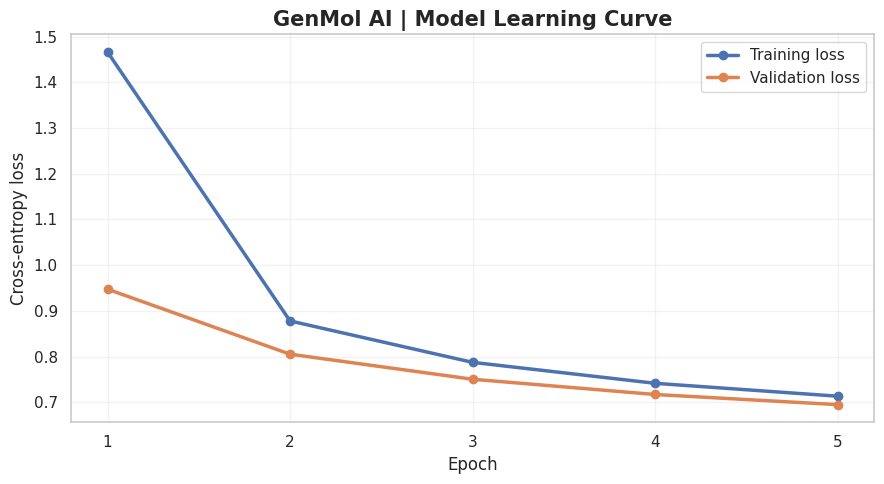

Learning curve saved to: /content/genmol_ai/figures/training_learning_curve.png


In [ ]:

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    history_df["epoch"],
    history_df["training_loss"],
    marker="o",
    linewidth=2.5,
    label="Training loss"
)

ax.plot(
    history_df["epoch"],
    history_df["validation_loss"],
    marker="o",
    linewidth=2.5,
    label="Validation loss"
)

ax.set_title(
    "GenMol AI | Model Learning Curve",
    fontsize=15,
    weight="bold"
)
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.set_xticks(history_df["epoch"].tolist())
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

figure_path = os.path.join(
    FIGURES_DIR,
    "training_learning_curve.png"
)

fig.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()

print(f"Learning curve saved to: {figure_path}")


In [ ]:

checkpoint_path = os.path.join(
    PROJECT_DIR,
    "genmol_lstm_checkpoint.pt"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "vocabulary": vocabulary,
    "token_to_id": token_to_id,
    "id_to_token": id_to_token,
    "pad_id": PAD_ID,
    "unk_id": UNK_ID,
    "start_id": START_ID,
    "end_id": END_ID,
    "embedding_dim": EMBEDDING_DIM,
    "hidden_dim": HIDDEN_DIM,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "max_sequence_length": MAX_SEQUENCE_LENGTH,
    "seed": SEED,
}, checkpoint_path)

print(f"Model checkpoint saved to: {checkpoint_path}")
print(f"Final training loss: {history_df['training_loss'].iloc[-1]:.4f}")
print(f"Final validation loss: {history_df['validation_loss'].iloc[-1]:.4f}")


Model checkpoint saved to: /content/genmol_ai/genmol_lstm_checkpoint.pt
Final training loss: 0.7132
Final validation loss: 0.6947


## Generate and Validate Novel Molecular Candidates

The trained LSTM generates candidate molecular structures by predicting molecular tokens sequentially. RDKit validates the resulting SMILES strings and calculates molecular properties. These candidates are computational research outputs, not proven drugs or evidence of biological activity.

In [ ]:
import torch
import torch.nn.functional as F
from rdkit import Chem
from rdkit.Chem import Descriptors, QED, Crippen, Lipinski
import pandas as pd
import numpy as np
import os
import random

GENERATION_SEED = 42
random.seed(GENERATION_SEED)
np.random.seed(GENERATION_SEED)
torch.manual_seed(GENERATION_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GENERATION_SEED)

print("Generation device:", DEVICE)
print("Vocabulary size:", len(vocabulary))
print("Maximum sequence length:", MAX_SEQUENCE_LENGTH)

Generation device: cuda
Vocabulary size: 38
Maximum sequence length: 150


In [ ]:
def generate_smiles(model, temperature=0.8, max_length=MAX_SEQUENCE_LENGTH):
    model.eval()
    generated_ids = [START_ID]

    with torch.no_grad():
        for _ in range(max_length - 1):
            input_ids = torch.tensor([generated_ids], dtype=torch.long, device=DEVICE)
            logits = model(input_ids)[:, -1, :] / temperature
            logits[:, PAD_ID] = -torch.inf
            logits[:, START_ID] = -torch.inf
            logits[:, UNK_ID] = -torch.inf
            probabilities = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probabilities, num_samples=1).item()

            if next_id == END_ID:
                break

            generated_ids.append(next_id)

    return decode_tokens(generated_ids[1:])


print("Generation function ready.")

Generation function ready.


In [ ]:
NUM_GENERATION_ATTEMPTS = 1000
generated_records = []

for attempt in range(NUM_GENERATION_ATTEMPTS):
    smiles = generate_smiles(model, temperature=0.8)

    if not smiles:
        continue

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        continue

    canonical_smiles = Chem.MolToSmiles(mol, canonical=True)

    generated_records.append({
        "smiles": smiles,
        "canonical_smiles": canonical_smiles,
        "molecular_weight": Descriptors.MolWt(mol),
        "logP": Crippen.MolLogP(mol),
        "qed": QED.qed(mol),
        "h_bond_donors": Lipinski.NumHDonors(mol),
        "h_bond_acceptors": Lipinski.NumHAcceptors(mol),
        "tpsa": Descriptors.TPSA(mol),
        "rotatable_bonds": Lipinski.NumRotatableBonds(mol),
        "heavy_atoms": Lipinski.HeavyAtomCount(mol)
    })

generated_df = pd.DataFrame(generated_records)

if not generated_df.empty:
    generated_df = generated_df.drop_duplicates(subset="canonical_smiles").reset_index(drop=True)

training_smiles = set(valid_df["canonical_smiles"].dropna().astype(str))
generated_df["is_novel_to_training_set"] = ~generated_df["canonical_smiles"].isin(training_smiles) if not generated_df.empty else pd.Series(dtype=bool)

generated_path = os.path.join(RESULTS_DIR, "generated_molecular_candidates.csv")
generated_df.to_csv(generated_path, index=False)

print("Generation attempts:", NUM_GENERATION_ATTEMPTS)
print("Unique valid candidates:", len(generated_df))
print("Candidates absent from the training set:", int(generated_df["is_novel_to_training_set"].sum()) if not generated_df.empty else 0)
print("Saved to:", generated_path)

[07:51:36] SMILES Parse Error: unclosed ring for input: 'CCOC(=O)c1ccc2c(c1)NC(=O)C(=O)NC1'
[07:51:37] Can't kekulize mol.  Unkekulized atoms: 2 3 4 5 21
[07:51:37] Can't kekulize mol.  Unkekulized atoms: 2 3 4 5 21
[07:51:37] Can't kekulize mol.  Unkekulized atoms: 2 3 4 5 30
[07:51:37] Can't kekulize mol.  Unkekulized atoms: 2 3 4 5 30
[07:51:37] SMILES Parse Error: unclosed ring for input: 'C[C@H](NC(=O)C1CCN(C(=O)c2ccccc2Cl)C2)c1'
[07:51:37] SMILES Parse Error: unclosed ring for input: 'CC[C@H]1C[NH2+]CCC[C@H]1N1C(=O)c1cccc2ccccc21'
[07:51:37] SMILES Parse Error: unclosed ring for input: 'CCCOC(=O)C1(CCl)C(C)(C)[NH+](CC(=O)N2CCCCC3)CC1'
[07:51:38] Can't kekulize mol.  Unkekulized atoms: 11 12 13 14 25
[07:51:38] Can't kekulize mol.  Unkekulized atoms: 11 12 13 14 25
[07:51:38] SMILES Parse Error: unclosed ring for input: 'CC(C)(C)c1ncc(NC(=O)N2C[C@@H](C)CC3(CN(C)C)CC2)cc1'
[07:51:38] Can't kekulize mol.  Unkekulized atoms: 12 13 15
[07:51:38] Can't kekulize mol.  Unkekulized atoms:

Generation attempts: 1000
Unique valid candidates: 717
Candidates absent from the training set: 716
Saved to: /content/genmol_ai/results/generated_molecular_candidates.csv


In [ ]:
if generated_df.empty:
    print("No valid candidates were generated. We will troubleshoot the generation settings before continuing.")
else:
    display(
        generated_df.sort_values(
            ["qed", "molecular_weight"],
            ascending=[False, True]
        ).head(15).round(3)
    )

    print("Validity rate:", f"{100 * len(generated_records) / NUM_GENERATION_ATTEMPTS:.1f}%")
    print("Unique-candidate rate among valid outputs:", f"{100 * len(generated_df) / max(len(generated_records), 1):.1f}%")
    print("Novelty rate against training set:", f"{100 * generated_df['is_novel_to_training_set'].mean():.1f}%")

,smiles,canonical_smiles,molecular_weight,logP,qed,h_bond_donors,h_bond_acceptors,tpsa,rotatable_bonds,heavy_atoms,is_novel_to_training_set
343,O=S(=O)(NC(=O)c1ccccc1)c1cccc(Cl)c1,O=C(NS(=O)(=O)c1cccc(Cl)c1)c1ccccc1,295.747,2.459,0.946,1,3,63.24,3,19,True
601,Cc1ccc(N2CCC(C(=O)Nc3cccnc3)CC2)cc1,Cc1ccc(N2CCC(C(=O)Nc3cccnc3)CC2)cc1,295.386,3.245,0.945,1,3,45.23,3,22,True
690,COc1cccc(C(=O)NC(=O)N2CCC[C@H]2c2ccccc2)c1,COc1cccc(C(=O)NC(=O)N2CCC[C@H]2c2ccccc2)c1,324.380,3.382,0.941,1,3,58.64,3,24,True
587,O=C([O-])Cc1ccc(NC(=O)c2ccc(Cl)c(F)c2)cc1,O=C([O-])Cc1ccc(NC(=O)c2ccc(Cl)c(F)c2)cc1,306.700,2.024,0.939,1,3,69.23,4,21,True
317,CCc1nn(-c2ccccc2)nc1N1CCC(C)[C@@H](O)C1,CCc1nn(-c2ccccc2)nc1N1CCC(C)[C@@H](O)C1,286.379,2.037,0.938,1,4,54.18,3,21,True
43,COc1cccc(NC(=O)c2cc(Cl)ccc2C)n1,COc1cccc(NC(=O)c2cc(Cl)ccc2C)n1,276.723,3.304,0.936,1,3,51.22,3,19,True
114,CCn1c(C(=O)Nc2ccc(Cl)c(Cl)c2)no1,CCn1onc1C(=O)Nc1ccc(Cl)c(Cl)c1,274.107,3.055,0.935,1,3,60.06,3,17,True
199,COc1ccc(NC(=O)c2ccc(Cl)cc2C#N)o1,COc1ccc(NC(=O)c2ccc(Cl)cc2C#N)o1,276.679,3.066,0.935,1,4,75.26,3,19,True
40,CC(=O)Nc1ccc([C@@H]2CCCCN2c2cccc(C)n2)c(C)n1,CC(=O)Nc1ccc([C@@H]2CCCCN2c2cccc(C)n2)c(C)n1,324.428,3.783,0.933,1,4,58.12,3,24,True
303,CC(C)c1ccc(C(=O)N2CCN([C@@H](C)C)C[C@H](O)C2)cc1,CC(C)c1ccc(C(=O)N2CCN(C(C)C)C[C@H](O)C2)cc1,304.434,2.337,0.932,1,3,43.78,3,22,True


Validity rate: 71.7%
Unique-candidate rate among valid outputs: 100.0%
Novelty rate against training set: 99.9%


In [ ]:
print("Dataset shape:", generated_df.shape)
print("Missing values:")
display(generated_df.isna().sum().to_frame("Missing count"))
print("Property summary:")
display(generated_df[["molecular_weight", "logP", "qed", "tpsa", "heavy_atoms"]].describe().round(2))
print("Top candidates by QED:")
display(generated_df.sort_values("qed", ascending=False)[["canonical_smiles", "molecular_weight", "logP", "qed", "tpsa", "is_novel_to_training_set"]].head(10).round(3))

Dataset shape: (717, 11)
Missing values:


,Missing count
smiles,0
canonical_smiles,0
molecular_weight,0
logP,0
qed,0
h_bond_donors,0
h_bond_acceptors,0
tpsa,0
rotatable_bonds,0
heavy_atoms,0


Property summary:


,molecular_weight,logP,qed,tpsa,heavy_atoms
count,717.00,717.00,717.00,717.00,717.00
mean,302.04,2.36,0.76,54.66,21.26
std,59.53,1.57,0.12,23.03,4.29
min,87.10,-2.63,0.26,0.00,6.00
25%,263.38,1.35,0.70,38.33,19.00
50%,298.75,2.45,0.79,51.78,21.00
75%,340.30,3.43,0.85,68.99,24.00
max,532.00,7.81,0.95,171.15,38.00


Top candidates by QED:


,canonical_smiles,molecular_weight,logP,qed,tpsa,is_novel_to_training_set
343,O=C(NS(=O)(=O)c1cccc(Cl)c1)c1ccccc1,295.747,2.459,0.946,63.24,True
601,Cc1ccc(N2CCC(C(=O)Nc3cccnc3)CC2)cc1,295.386,3.245,0.945,45.23,True
690,COc1cccc(C(=O)NC(=O)N2CCC[C@H]2c2ccccc2)c1,324.380,3.382,0.941,58.64,True
587,O=C([O-])Cc1ccc(NC(=O)c2ccc(Cl)c(F)c2)cc1,306.700,2.024,0.939,69.23,True
317,CCc1nn(-c2ccccc2)nc1N1CCC(C)[C@@H](O)C1,286.379,2.037,0.938,54.18,True
43,COc1cccc(NC(=O)c2cc(Cl)ccc2C)n1,276.723,3.304,0.936,51.22,True
114,CCn1onc1C(=O)Nc1ccc(Cl)c(Cl)c1,274.107,3.055,0.935,60.06,True
199,COc1ccc(NC(=O)c2ccc(Cl)cc2C#N)o1,276.679,3.066,0.935,75.26,True
40,CC(=O)Nc1ccc([C@@H]2CCCCN2c2cccc(C)n2)c(C)n1,324.428,3.783,0.933,58.12,True
303,CC(C)c1ccc(C(=O)N2CCN(C(C)C)C[C@H](O)C2)cc1,304.434,2.337,0.932,43.78,True


## Molecular Quality Control and Candidate Selection

Re-canonicalize the generated structures, remove any structures that fail revalidation, and shortlist candidates using molecular-property filters. These filters prioritize manageable, drug-like structures but do not establish biological activity or safety.

In [ ]:
from rdkit import rdBase

rdBase.DisableLog("rdApp.error")

clean_records = []

for _, row in generated_df.iterrows():
    mol = Chem.MolFromSmiles(str(row["canonical_smiles"]))

    if mol is None:
        continue

    canonical = Chem.MolToSmiles(mol, canonical=True)

    clean_records.append({
        "smiles": canonical,
        "canonical_smiles": canonical,
        "molecular_weight": Descriptors.MolWt(mol),
        "logP": Crippen.MolLogP(mol),
        "qed": QED.qed(mol),
        "h_bond_donors": Lipinski.NumHDonors(mol),
        "h_bond_acceptors": Lipinski.NumHAcceptors(mol),
        "tpsa": Descriptors.TPSA(mol),
        "rotatable_bonds": Lipinski.NumRotatableBonds(mol),
        "heavy_atoms": Lipinski.HeavyAtomCount(mol)
    })

clean_generated_df = pd.DataFrame(clean_records)
clean_generated_df = clean_generated_df.drop_duplicates(subset="canonical_smiles").reset_index(drop=True)
clean_generated_df["is_novel_to_training_set"] = ~clean_generated_df["canonical_smiles"].isin(training_smiles)

print("Candidates before revalidation:", len(generated_df))
print("Candidates after revalidation:", len(clean_generated_df))
print("Unique canonical structures:", clean_generated_df["canonical_smiles"].nunique())

clean_path = os.path.join(RESULTS_DIR, "clean_generated_candidates.csv")
clean_generated_df.to_csv(clean_path, index=False)
print("Saved:", clean_path)

Candidates before revalidation: 717
Candidates after revalidation: 717
Unique canonical structures: 717
Saved: /content/genmol_ai/results/clean_generated_candidates.csv


In [ ]:
candidate_pool = clean_generated_df[
    clean_generated_df["molecular_weight"].between(150, 500)
    & clean_generated_df["logP"].between(-1, 5)
    & (clean_generated_df["h_bond_donors"] <= 5)
    & (clean_generated_df["h_bond_acceptors"] <= 10)
    & (clean_generated_df["tpsa"] <= 140)
    & (clean_generated_df["rotatable_bonds"] <= 10)
].copy()

candidate_pool = candidate_pool.sort_values(
    ["qed", "molecular_weight"],
    ascending=[False, True]
).reset_index(drop=True)

candidate_path = os.path.join(RESULTS_DIR, "filtered_candidate_pool.csv")
candidate_pool.to_csv(candidate_path, index=False)

print("Revalidated molecules:", len(clean_generated_df))
print("Candidates passing property filters:", len(candidate_pool))
print("Saved:", candidate_path)

display(
    candidate_pool[
        ["canonical_smiles", "molecular_weight", "logP", "qed",
         "h_bond_donors", "h_bond_acceptors", "tpsa",
         "rotatable_bonds", "is_novel_to_training_set"]
    ].head(15).round(3)
)

Revalidated molecules: 717
Candidates passing property filters: 671
Saved: /content/genmol_ai/results/filtered_candidate_pool.csv


,canonical_smiles,molecular_weight,logP,qed,h_bond_donors,h_bond_acceptors,tpsa,rotatable_bonds,is_novel_to_training_set
0,O=C(NS(=O)(=O)c1cccc(Cl)c1)c1ccccc1,295.747,2.459,0.946,1,3,63.24,3,True
1,Cc1ccc(N2CCC(C(=O)Nc3cccnc3)CC2)cc1,295.386,3.245,0.945,1,3,45.23,3,True
2,COc1cccc(C(=O)NC(=O)N2CCC[C@H]2c2ccccc2)c1,324.380,3.382,0.941,1,3,58.64,3,True
3,O=C([O-])Cc1ccc(NC(=O)c2ccc(Cl)c(F)c2)cc1,306.700,2.024,0.939,1,3,69.23,4,True
4,CCc1nn(-c2ccccc2)nc1N1CCC(C)[C@@H](O)C1,286.379,2.037,0.938,1,4,54.18,3,True
5,COc1cccc(NC(=O)c2cc(Cl)ccc2C)n1,276.723,3.304,0.936,1,3,51.22,3,True
6,CCn1onc1C(=O)Nc1ccc(Cl)c(Cl)c1,274.107,3.055,0.935,1,3,60.06,3,True
7,COc1ccc(NC(=O)c2ccc(Cl)cc2C#N)o1,276.679,3.066,0.935,1,4,75.26,3,True
8,CC(=O)Nc1ccc([C@@H]2CCCCN2c2cccc(C)n2)c(C)n1,324.428,3.783,0.933,1,4,58.12,3,True
9,CC(C)c1ccc(C(=O)N2CCN(C(C)C)C[C@H](O)C2)cc1,304.434,2.337,0.932,1,3,43.78,3,True


## EGFR Target Preparation and Molecular Docking

This stage prepares the EGFR protein structure and candidate ligands for structure-based virtual screening. We will first verify the downloaded structure and its reference ligand before docking generated molecules.

In [ ]:
import sys
import subprocess

print("Python version:", sys.version)

packages = ["biopython", "gemmi", "vina", "meeko"]

for package in packages:
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", package],
        capture_output=True,
        text=True
    )
    print(f"\n{package}: {'SUCCESS' if result.returncode == 0 else 'FAILED'}")
    if result.returncode != 0:
        print((result.stderr or result.stdout)[-2500:])

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

biopython: SUCCESS

gemmi: SUCCESS

vina: FAILED
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
ERROR: Failed to build 'vina' when getting requirements to build wheel


meeko: SUCCESS


In [ ]:
import os
import urllib.request
from Bio.PDB import PDBParser

PDB_ID = "1M17"
TARGET_DIR = os.path.join(PROJECT_DIR, "target")
os.makedirs(TARGET_DIR, exist_ok=True)

pdb_path = os.path.join(TARGET_DIR, f"{PDB_ID}.pdb")
pdb_url = f"https://files.rcsb.org/download/{PDB_ID}.pdb"

urllib.request.urlretrieve(pdb_url, pdb_path)

parser = PDBParser(QUIET=True)
structure = parser.get_structure(PDB_ID, pdb_path)
model_structure = structure[0]

protein_residues = [
    residue for residue in model_structure.get_residues()
    if residue.id[0] == " "
]

ligand_residues = [
    residue for residue in model_structure.get_residues()
    if residue.id[0].startswith("H_")
]

print("PDB ID:", PDB_ID)
print("Structure file:", pdb_path)
print("Protein residues:", len(protein_residues))
print("Heterogeneous residues:", len(ligand_residues))
print("Chains:", [chain.id for chain in model_structure.get_chains()])
print("Structure size:", f"{os.path.getsize(pdb_path) / 1024:.1f} KB")

print("Non-protein residues:")
print(sorted({residue.resname for residue in ligand_residues}))

PDB ID: 1M17
Structure file: /content/genmol_ai/target/1M17.pdb
Protein residues: 312
Heterogeneous residues: 1
Chains: ['A']
Structure size: 246.8 KB
Non-protein residues:
['AQ4']


In [ ]:
import numpy as np
from Bio.PDB import PDBParser

structure = PDBParser(QUIET=True).get_structure("EGFR", pdb_path)
model_structure = structure[0]

reference_ligand = None

for residue in model_structure.get_residues():
    if residue.resname == "AQ4":
        reference_ligand = residue
        break

if reference_ligand is None:
    raise ValueError("Reference ligand AQ4 was not found in the structure.")

ligand_atoms = [
    atom for atom in reference_ligand.get_atoms()
    if atom.element not in {"H", "D"}
]

ligand_coordinates = np.array([atom.coord for atom in ligand_atoms])

pocket_center = ligand_coordinates.mean(axis=0)
ligand_min = ligand_coordinates.min(axis=0)
ligand_max = ligand_coordinates.max(axis=0)
ligand_extent = ligand_max - ligand_min

BOX_PADDING = 10.0
box_size = ligand_extent + BOX_PADDING

print("Reference ligand:", reference_ligand.resname)
print("Heavy atoms:", len(ligand_atoms))
print("Pocket center (x, y, z):", np.round(pocket_center, 3))
print("Ligand extent (Å):", np.round(ligand_extent, 3))
print("Docking box size (Å):", np.round(box_size, 3))

np.savez(
    os.path.join(TARGET_DIR, "egfr_binding_site.npz"),
    center=pocket_center,
    box_size=box_size
)

print("Binding-site coordinates saved.")

Reference ligand: AQ4
Heavy atoms: 29
Pocket center (x, y, z): [22.014  0.253 52.794]
Ligand extent (Å): [15.709  4.684  7.099]
Docking box size (Å): [25.709 14.684 17.099]
Binding-site coordinates saved.


In [ ]:
import sys
import importlib.util
import shutil

print("Python:", sys.version.split()[0])

for package in ["Bio", "rdkit", "vina", "meeko", "gemmi"]:
    print(f"{package}: {'available' if importlib.util.find_spec(package) else 'not installed'}")

for command in ["mk_prepare_receptor.py", "mk_prepare_ligand.py", "obabel"]:
    print(f"{command}: {shutil.which(command) or 'not found'}")

Python: 3.13.16
Bio: available
rdkit: available
vina: not installed
meeko: available
gemmi: available
mk_prepare_receptor.py: /usr/local/bin/mk_prepare_receptor.py
mk_prepare_ligand.py: /usr/local/bin/mk_prepare_ligand.py
obabel: not found


In [ ]:
import os
import json
import urllib.request
import subprocess

release_url = "https://api.github.com/repos/ccsb-scripps/AutoDock-Vina/releases/latest"

request = urllib.request.Request(
    release_url,
    headers={"User-Agent": "GenMol-AI-Colab"}
)

with urllib.request.urlopen(request, timeout=30) as response:
    release = json.loads(response.read().decode("utf-8"))

assets = release.get("assets", [])
matches = [
    asset for asset in assets
    if "linux" in asset["name"].lower()
    and ("x86_64" in asset["name"].lower() or "x86-64" in asset["name"].lower())
    and asset["name"].lower().startswith("vina_")
    and "split" not in asset["name"].lower()
    and not asset["name"].lower().endswith(".tar.gz")
]

if not matches:
    print("Available release assets:")
    for asset in assets:
        print(asset["name"])
    raise RuntimeError("Could not identify the Linux x86_64 Vina executable.")

vina_asset = matches[0]
vina_binary = os.path.join(PROJECT_DIR, "vina")

urllib.request.urlretrieve(vina_asset["browser_download_url"], vina_binary)
os.chmod(vina_binary, 0o755)

result = subprocess.run(
    [vina_binary, "--help"],
    capture_output=True,
    text=True,
    timeout=30
)

print("Release:", release.get("tag_name"))
print("Downloaded:", vina_asset["name"])
print("Executable test:", "SUCCESS" if result.returncode == 0 else "FAILED")
print((result.stdout or result.stderr)[:1800])

if result.returncode != 0:
    raise RuntimeError("Vina executable did not pass its help test.")

Release: v1.2.7
Downloaded: vina_1.2.7_linux_x86_64
Executable test: SUCCESS
AutoDock Vina v1.2.7

Input:
  --receptor arg             rigid part of the receptor (PDBQT)
  --flex arg                 flexible side chains, if any (PDBQT)
  --ligand arg               ligand (PDBQT)
  --batch arg                batch directory or ligands (PDBQT)
  --scoring arg (=vina)      scoring function (ad4, vina or vinardo)

Search space (required):
  --maps arg                 affinity maps for the autodock4.2 (ad4) or vina 
                             scoring function
  --center_x arg             X coordinate of the center (Angstrom)
  --center_y arg             Y coordinate of the center (Angstrom)
  --center_z arg             Z coordinate of the center (Angstrom)
  --size_x arg               size in the X dimension (Angstrom)
  --size_y arg               size in the Y dimension (Angstrom)
  --size_z arg               size in the Z dimension (Angstrom)
  --autobox                  set maps dimens

In [ ]:
import os
import subprocess

protein_pdb_path = os.path.join(TARGET_DIR, "egfr_protein_only.pdb")
receptor_prefix = os.path.join(TARGET_DIR, "egfr_receptor")
receptor_pdbqt_path = receptor_prefix + ".pdbqt"

with open(pdb_path, "r") as source:
    pdb_lines = source.readlines()

protein_lines = [
    line for line in pdb_lines
    if line.startswith("ATOM  ")
    and line[21:22] == "A"
]

with open(protein_pdb_path, "w") as output:
    output.writelines(protein_lines)
    output.write("TER\nEND\n")

print("Protein ATOM records:", len(protein_lines))
print("Protein-only PDB:", protein_pdb_path)

prep_result = subprocess.run(
    [
        "mk_prepare_receptor.py",
        "--read_pdb", protein_pdb_path,
        "-o", receptor_prefix,
        "-p"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print("Preparation exit code:", prep_result.returncode)
print((prep_result.stdout or "")[-2500:])

if prep_result.returncode != 0:
    print((prep_result.stderr or "")[-4000:])
else:
    possible_outputs = [
        receptor_pdbqt_path,
        receptor_prefix + "_rigid.pdbqt"
    ]
    receptor_pdbqt_path = next(
        (path for path in possible_outputs if os.path.exists(path)),
        None
    )
    print("Receptor PDBQT:", receptor_pdbqt_path)
    print("Preparation successful:", receptor_pdbqt_path is not None)

Protein ATOM records: 2511
Protein-only PDB: /content/genmol_ai/target/egfr_protein_only.pdb
Preparation exit code: 1
Template padding will be used.
 gasteiger charges will be read from template file 
 

Error: Creation of data structure for receptor failed.

Details:
- Residues with alternate location: ['A:751', 'A:831']
Either specify an altloc for each with option wanted_altloc
or a general default altloc with option default_altloc.
Recommendations:
1. (for batch processing) Use -a/--allow_bad_res to automatically remove residues
that do not match templates, and --default_altloc to set
a default altloc variant. Use these at your own risk.

2. (processing individual structure) Inspecting and fixing the input structure is recommended.
Use --wanted_altloc to set variants for specific residues.






In [ ]:
from collections import defaultdict
import os
import subprocess

protein_pdb_path = os.path.join(TARGET_DIR, "egfr_protein_clean.pdb")
receptor_prefix = os.path.join(TARGET_DIR, "egfr_receptor")

with open(pdb_path, "r") as source:
    pdb_lines = source.readlines()

atom_groups = defaultdict(list)
other_lines = []

for line in pdb_lines:
    if line.startswith("ATOM  ") and line[21:22] == "A":
        key = (line[21:22], line[22:27], line[12:16])
        atom_groups[key].append(line)
    elif line.startswith(("TER", "END")):
        continue

selected_lines = []

for atom_lines in atom_groups.values():
    blank_altloc = [line for line in atom_lines if line[16] == " "]
    altloc_a = [line for line in atom_lines if line[16] == "A"]
    choices = blank_altloc or altloc_a or atom_lines
    chosen = max(choices, key=lambda line: float(line[54:60].strip() or 0))
    selected_lines.append(chosen[:16] + " " + chosen[17:])

selected_lines.sort(key=lambda line: (line[21:22], int(line[22:26]), line[12:16]))

with open(protein_pdb_path, "w") as output:
    output.writelines(selected_lines)
    output.write("TER\nEND\n")

prep_result = subprocess.run(
    [
        "mk_prepare_receptor.py",
        "--read_pdb", protein_pdb_path,
        "-o", receptor_prefix,
        "-p"
    ],
    capture_output=True,
    text=True,
    timeout=180
)

print("Preparation exit code:", prep_result.returncode)
print((prep_result.stdout or "")[-1800:])

if prep_result.returncode != 0:
    print((prep_result.stderr or "")[-3000:])
else:
    receptor_candidates = [
        receptor_prefix + ".pdbqt",
        receptor_prefix + "_rigid.pdbqt"
    ]
    receptor_pdbqt_path = next(
        (path for path in receptor_candidates if os.path.exists(path)),
        None
    )
    print("Receptor PDBQT:", receptor_pdbqt_path)
    print("Preparation successful:", receptor_pdbqt_path is not None)

Preparation exit code: 0
Template padding will be used.
 gasteiger charges will be read from template file 
 

Files written:
/content/genmol_ai/target/egfr_receptor.pdbqt <-- static (i.e., rigid) receptor input file

Receptor PDBQT: /content/genmol_ai/target/egfr_receptor.pdbqt
Preparation successful: True


In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem
from meeko import MoleculePreparation, PDBQTWriterLegacy
import os
import pandas as pd

LIGAND_DIR = os.path.join(TARGET_DIR, "ligands")
os.makedirs(LIGAND_DIR, exist_ok=True)

docking_candidates = candidate_pool.head(20).copy()
prepared_records = []
failed_records = []

for candidate_index, row in docking_candidates.iterrows():
    smiles = str(row["canonical_smiles"])
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        failed_records.append({"candidate_index": int(candidate_index), "reason": "Invalid SMILES"})
        continue

    mol = Chem.AddHs(mol)
    conformer_status = AllChem.EmbedMolecule(mol, randomSeed=42 + int(candidate_index))

    if conformer_status != 0:
        failed_records.append({"candidate_index": int(candidate_index), "reason": "3D embedding failed"})
        continue

    AllChem.MMFFOptimizeMolecule(mol, maxIters=200)

    try:
        preparation = MoleculePreparation()
        setups = preparation.prepare(mol)
        setup = setups[0]
        pdbqt_text, is_ok, error_message = PDBQTWriterLegacy.write_string(setup)

        if not is_ok:
            failed_records.append({"candidate_index": int(candidate_index), "reason": str(error_message)})
            continue

        ligand_path = os.path.join(LIGAND_DIR, f"candidate_{candidate_index:04d}.pdbqt")

        with open(ligand_path, "w") as output:
            output.write(pdbqt_text)

        prepared_records.append({
            "candidate_index": int(candidate_index),
            "canonical_smiles": smiles,
            "ligand_path": ligand_path,
            "qed": float(row["qed"]),
            "molecular_weight": float(row["molecular_weight"]),
            "logP": float(row["logP"])
        })

    except Exception as error:
        failed_records.append({"candidate_index": int(candidate_index), "reason": str(error)[:300]})

prepared_df = pd.DataFrame(prepared_records)
failed_df = pd.DataFrame(failed_records)

print("Candidates attempted:", len(docking_candidates))
print("Ligands prepared:", len(prepared_df))
print("Preparation failures:", len(failed_df))

if not prepared_df.empty:
    display(prepared_df.head())

if not failed_df.empty:
    display(failed_df.head())

Candidates attempted: 20
Ligands prepared: 20
Preparation failures: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,candidate_index,canonical_smiles,ligand_path,qed,molecular_weight,logP
0,0,O=C(NS(=O)(=O)c1cccc(Cl)c1)c1ccccc1,/content/genmol_ai/target/ligands/candidate_00...,0.945857,295.747,2.45870
1,1,Cc1ccc(N2CCC(C(=O)Nc3cccnc3)CC2)cc1,/content/genmol_ai/target/ligands/candidate_00...,0.945162,295.386,3.24512
2,2,COc1cccc(C(=O)NC(=O)N2CCC[C@H]2c2ccccc2)c1,/content/genmol_ai/target/ligands/candidate_00...,0.941373,324.380,3.38210
3,3,O=C([O-])Cc1ccc(NC(=O)c2ccc(Cl)c(F)c2)cc1,/content/genmol_ai/target/ligands/candidate_00...,0.939318,306.700,2.02380
4,4,CCc1nn(-c2ccccc2)nc1N1CCC(C)[C@@H](O)C1,/content/genmol_ai/target/ligands/candidate_00...,0.937859,286.379,2.03680


In [ ]:
import subprocess
import os
import re
import pandas as pd
import numpy as np

with np.load(os.path.join(TARGET_DIR, "egfr_binding_site.npz")) as site:
    center = site["center"]
    box = site["box_size"]

DOCKING_DIR = os.path.join(RESULTS_DIR, "egfr_docking")
os.makedirs(DOCKING_DIR, exist_ok=True)

docking_results = []

for _, candidate in prepared_df.iterrows():
    candidate_id = int(candidate["candidate_index"])
    ligand_path = str(candidate["ligand_path"])
    output_path = os.path.join(DOCKING_DIR, f"candidate_{candidate_id:04d}_pose.pdbqt")
    log_path = os.path.join(DOCKING_DIR, f"candidate_{candidate_id:04d}.log")

    command = [
        vina_binary,
        "--receptor", receptor_pdbqt_path,
        "--ligand", ligand_path,
        "--center_x", str(float(center[0])),
        "--center_y", str(float(center[1])),
        "--center_z", str(float(center[2])),
        "--size_x", str(float(box[0])),
        "--size_y", str(float(box[1])),
        "--size_z", str(float(box[2])),
        "--exhaustiveness", "8",
        "--num_modes", "3",
        "--seed", "42",
        "--out", output_path
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=180
    )

    log_text = (result.stdout or "") + "\n" + (result.stderr or "")

    with open(log_path, "w") as log_file:
        log_file.write(log_text)

    scores = re.findall(
        r"^\s*1\s+(-?\d+(?:\.\d+)?)\s+",
        log_text,
        flags=re.MULTILINE
    )

    docking_results.append({
        "candidate_index": candidate_id,
        "canonical_smiles": candidate["canonical_smiles"],
        "qed": float(candidate["qed"]),
        "molecular_weight": float(candidate["molecular_weight"]),
        "logP": float(candidate["logP"]),
        "docking_score_kcal_mol": float(scores[0]) if result.returncode == 0 and scores else np.nan,
        "docking_success": result.returncode == 0 and bool(scores),
        "pose_path": output_path if result.returncode == 0 and os.path.exists(output_path) else "",
        "log_path": log_path,
        "error": "" if result.returncode == 0 and scores else log_text[-1000:]
    })

    print(
        f"Candidate {candidate_id}:",
        f"{scores[0]} kcal/mol" if result.returncode == 0 and scores else "FAILED"
    )

docking_df = pd.DataFrame(docking_results)
docking_df = docking_df.sort_values(
    "docking_score_kcal_mol",
    ascending=True,
    na_position="last"
).reset_index(drop=True)

docking_csv = os.path.join(DOCKING_DIR, "egfr_docking_ranked.csv")
docking_df.to_csv(docking_csv, index=False)

print("\nDocking completed:", int(docking_df["docking_success"].sum()), "/", len(docking_df))
print("Results saved:", docking_csv)

display(
    docking_df[
        ["candidate_index", "docking_score_kcal_mol", "qed", "molecular_weight", "docking_success"]
    ].round(3)
)

Candidate 0: -7.53 kcal/mol
Candidate 1: -7.538 kcal/mol
Candidate 2: -8.298 kcal/mol
Candidate 3: -7.371 kcal/mol
Candidate 4: -7.371 kcal/mol
Candidate 5: -7.296 kcal/mol
Candidate 6: -6.823 kcal/mol
Candidate 7: -7.424 kcal/mol
Candidate 8: -7.841 kcal/mol
Candidate 9: -5.89 kcal/mol
Candidate 10: -7.47 kcal/mol
Candidate 11: -6.676 kcal/mol
Candidate 12: -6.889 kcal/mol
Candidate 13: -6.647 kcal/mol
Candidate 14: -6.833 kcal/mol
Candidate 15: -7.497 kcal/mol
Candidate 16: -5.194 kcal/mol
Candidate 17: -6.653 kcal/mol
Candidate 18: -5.174 kcal/mol
Candidate 19: -7.735 kcal/mol

Docking completed: 20 / 20
Results saved: /content/genmol_ai/results/egfr_docking/egfr_docking_ranked.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,candidate_index,docking_score_kcal_mol,qed,molecular_weight,docking_success
0,2,-8.298,0.941,324.380,True
1,8,-7.841,0.933,324.428,True
2,19,-7.735,0.922,275.735,True
3,1,-7.538,0.945,295.386,True
4,0,-7.530,0.946,295.747,True
5,15,-7.497,0.926,303.406,True
6,10,-7.470,0.929,279.698,True
7,7,-7.424,0.935,276.679,True
8,4,-7.371,0.938,286.379,True
9,3,-7.371,0.939,306.700,True


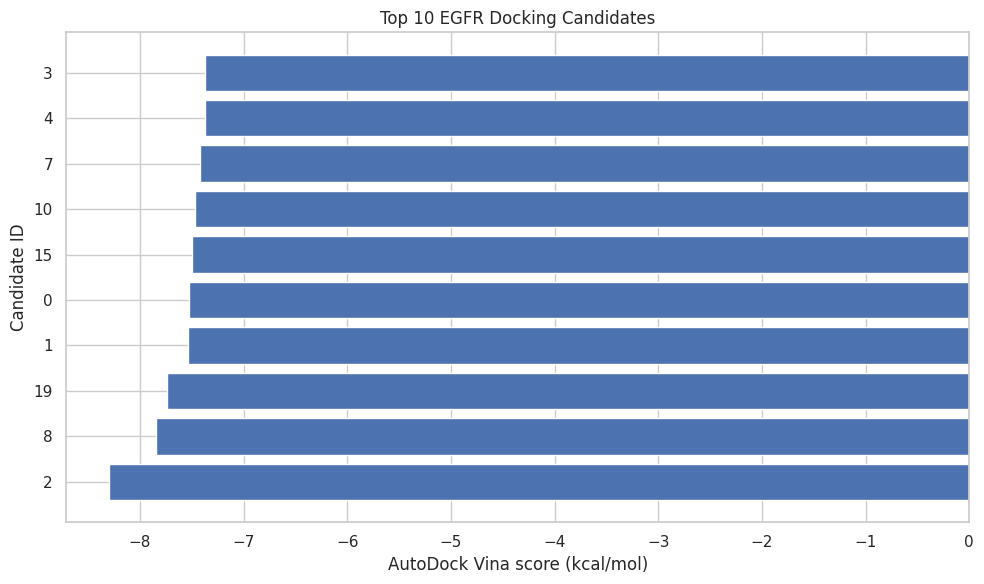

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


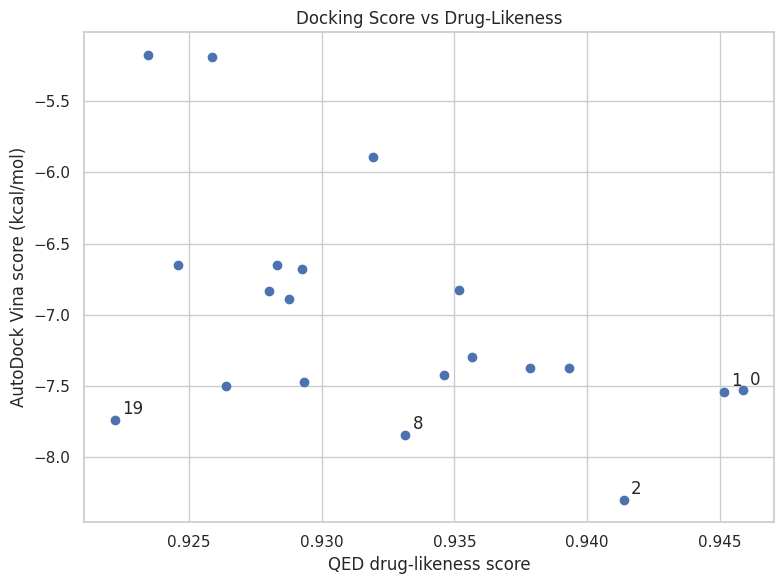

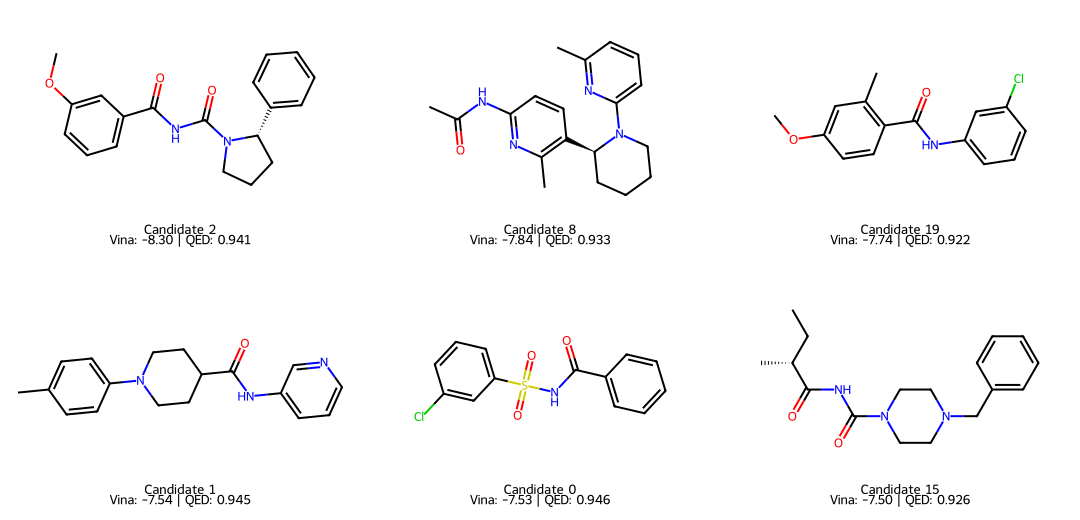

Visualization files saved in: /content/genmol_ai/figures


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,candidate_index,canonical_smiles,docking_score_kcal_mol,qed,molecular_weight
0,2,COc1cccc(C(=O)NC(=O)N2CCC[C@H]2c2ccccc2)c1,-8.298,0.941373,324.380
1,8,CC(=O)Nc1ccc([C@@H]2CCCCN2c2cccc(C)n2)c(C)n1,-7.841,0.933159,324.428
2,19,COc1ccc(C(=O)Nc2cccc(Cl)c2)c(C)c1,-7.735,0.922225,275.735
3,1,Cc1ccc(N2CCC(C(=O)Nc3cccnc3)CC2)cc1,-7.538,0.945162,295.386
4,0,O=C(NS(=O)(=O)c1cccc(Cl)c1)c1ccccc1,-7.530,0.945857,295.747


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display

DOCKING_DIR = "/content/genmol_ai/results/egfr_docking"
FIGURES_DIR = "/content/genmol_ai/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

docking_csv = os.path.join(DOCKING_DIR, "egfr_docking_ranked.csv")

if "docking_df" in globals() and isinstance(docking_df, pd.DataFrame):
    results = docking_df.copy()
elif os.path.exists(docking_csv):
    results = pd.read_csv(docking_csv)
else:
    raise FileNotFoundError(
        "Docking CSV not found. Check that you are in the same Colab runtime "
        "and rerun the docking cell if needed."
    )

results["docking_score_kcal_mol"] = pd.to_numeric(
    results["docking_score_kcal_mol"], errors="coerce"
)
results["qed"] = pd.to_numeric(results["qed"], errors="coerce")
results["candidate_index"] = pd.to_numeric(
    results["candidate_index"], errors="coerce"
)

successful = results.dropna(
    subset=["docking_score_kcal_mol", "qed", "candidate_index"]
).sort_values("docking_score_kcal_mol")

if successful.empty:
    raise ValueError("No valid docking scores are available to plot.")

successful.to_csv(docking_csv, index=False)

top10 = successful.head(10).sort_values("docking_score_kcal_mol")

plt.figure(figsize=(10, 6))
plt.barh(
    top10["candidate_index"].astype(int).astype(str),
    top10["docking_score_kcal_mol"]
)
plt.xlabel("AutoDock Vina score (kcal/mol)")
plt.ylabel("Candidate ID")
plt.title("Top 10 EGFR Docking Candidates")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "egfr_docking_scores.png"), dpi=220)
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(successful["qed"], successful["docking_score_kcal_mol"])

for _, row in successful.head(5).iterrows():
    plt.annotate(
        str(int(row["candidate_index"])),
        (row["qed"], row["docking_score_kcal_mol"]),
        xytext=(5, 4),
        textcoords="offset points"
    )

plt.xlabel("QED drug-likeness score")
plt.ylabel("AutoDock Vina score (kcal/mol)")
plt.title("Docking Score vs Drug-Likeness")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "docking_vs_qed.png"), dpi=220)
plt.show()

top6 = successful.head(6)
molecules = []
legends = []

for _, row in top6.iterrows():
    mol = Chem.MolFromSmiles(str(row["canonical_smiles"]))
    if mol is not None:
        molecules.append(mol)
        legends.append(
            f"Candidate {int(row['candidate_index'])}\n"
            f"Vina: {row['docking_score_kcal_mol']:.2f} | QED: {row['qed']:.3f}"
        )

if molecules:
    # Using returnPNG=True or standard MolsToGridImage with useSVG=False returns a PIL image in modern RDKit versions.
    # We explicitly convert or save through PIL helper or ensure we call the helper function.
    gallery = Draw.MolsToGridImage(
        molecules, molsPerRow=3, subImgSize=(360, 260),
        legends=legends, useSVG=False
    )

    # Safeguard: If RDKit returns a wrapper or IPython Image, we get the actual PIL Image or save data directly
    if hasattr(gallery, "save"):
        gallery.save(os.path.join(FIGURES_DIR, "top6_candidate_structures.png"))
    elif hasattr(gallery, "data"):
        with open(os.path.join(FIGURES_DIR, "top6_candidate_structures.png"), "wb") as f:
            f.write(gallery.data)

    display(gallery)

print("Visualization files saved in:", FIGURES_DIR)
display(
    successful.head(5)[
        ["candidate_index", "canonical_smiles",
         "docking_score_kcal_mol", "qed", "molecular_weight"]
    ]
)

In [ ]:

%pip install -q gradio


In [ ]:

import os
import pandas as pd
import gradio as gr
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display

docking_path = "/content/genmol_ai/results/egfr_docking/egfr_docking_ranked.csv"
results = pd.read_csv(docking_path)
results = results.dropna(subset=["docking_score_kcal_mol", "qed"])
results = results.sort_values("docking_score_kcal_mol").reset_index(drop=True)

def inspect_candidate(candidate_id):
    selected = results[results["candidate_index"] == int(candidate_id)]

    if selected.empty:
        return None, "Candidate not found.", ""

    row = selected.iloc[0]
    mol = Chem.MolFromSmiles(str(row["canonical_smiles"]))

    if mol is None:
        return None, "Could not render this molecular structure.", str(row["canonical_smiles"])

    image = Draw.MolToImage(mol, size=(500, 400))

    details = (
        f"### Candidate {int(row['candidate_index'])}\n\n"
        f"- **Predicted EGFR docking score:** {row['docking_score_kcal_mol']:.3f} kcal/mol\n"
        f"- **QED drug-likeness:** {row['qed']:.3f}\n"
        f"- **Molecular weight:** {row['molecular_weight']:.3f} g/mol\n"
        f"- **Calculated logP:** {row['logP']:.3f}\n\n"
        "These are computational predictions, not experimental evidence of drug activity."
    )

    return image, details, str(row["canonical_smiles"])

candidate_ids = results["candidate_index"].astype(int).tolist()

with gr.Blocks(title="GenMol AI Research Lab") as demo:
    gr.Markdown("# GenMol AI — Molecular Candidate Explorer")
    gr.Markdown(
        "Explore generated molecular candidates ranked by predicted EGFR docking score. "
        "A more negative Vina score indicates a more favorable predicted docking score "
        "under the chosen setup; it does not establish biological activity."
    )

    candidate_selector = gr.Dropdown(
        choices=[(f"Candidate {int(row['candidate_index'])} — {row['docking_score_kcal_mol']:.3f} kcal/mol",
                  int(row["candidate_index"])) for _, row in results.iterrows()],
        value=int(results.iloc[0]["candidate_index"]),
        label="Select a candidate"
    )

    with gr.Row():
        molecule_image = gr.Image(label="2D molecular structure", type="pil")
        candidate_details = gr.Markdown()

    smiles_output = gr.Textbox(label="Canonical SMILES", lines=3)

    candidate_selector.change(
        fn=inspect_candidate,
        inputs=candidate_selector,
        outputs=[molecule_image, candidate_details, smiles_output]
    )

    demo.load(
        fn=inspect_candidate,
        inputs=candidate_selector,
        outputs=[molecule_image, candidate_details, smiles_output]
    )

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


* Running on public URL: https://aa0e49657cc9019747.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

import os
import pandas as pd
from datetime import date

BASE_DIR = "/content/genmol_ai"
DATA_DIR = os.path.join(BASE_DIR, "data")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
FIGURES_DIR = os.path.join(BASE_DIR, "figures")

generated_path = os.path.join(RESULTS_DIR, "generated_molecular_candidates.csv")
filtered_path = os.path.join(RESULTS_DIR, "filtered_candidate_pool.csv")
docking_path = os.path.join(RESULTS_DIR, "egfr_docking", "egfr_docking_ranked.csv")

generated = pd.read_csv(generated_path)
filtered = pd.read_csv(filtered_path)
docking = pd.read_csv(docking_path)

docking["docking_score_kcal_mol"] = pd.to_numeric(
    docking["docking_score_kcal_mol"], errors="coerce"
)
docking["qed"] = pd.to_numeric(docking["qed"], errors="coerce")

successful = docking.dropna(subset=["docking_score_kcal_mol"]).sort_values(
    "docking_score_kcal_mol"
)

if successful.empty:
    raise ValueError("No successful docking results were found.")

best = successful.iloc[0]

summary = {
    "Project": "GenMol AI",
    "Research focus": "Generative molecular design and exploratory EGFR virtual screening",
    "Dataset": "ZINC-derived molecular dataset",
    "Dataset rows": 249455,
    "Unique valid generated molecules": len(generated),
    "Candidates passing property filters": len(filtered),
    "Candidates attempted in docking": len(docking),
    "Successful docking runs": len(successful),
    "Best candidate ID": int(best["candidate_index"]),
    "Best predicted docking score (kcal/mol)": float(best["docking_score_kcal_mol"]),
    "Best candidate QED": float(best["qed"]),
    "Evaluation target": "EGFR structure PDB 1M17",
    "Reference ligand residue in structure": "AQ4",
    "Report generated": str(date.today())
}

summary_df = pd.DataFrame(
    [{"Metric": key, "Value": value} for key, value in summary.items()]
)
summary_path = os.path.join(RESULTS_DIR, "final_project_summary.csv")
summary_df.to_csv(summary_path, index=False)

report = f"""# GenMol AI — Final Research Summary

## Objective
Develop an exploratory computational pipeline that generates molecular structures,
filters candidates using physicochemical properties, and ranks selected molecules
using predicted docking scores against an EGFR protein structure.

## Dataset and generation
- Dataset: ZINC-derived molecular dataset.
- Dataset rows: 249,455.
- Valid unique generated molecules: {len(generated)}.
- Candidates passing preliminary property filters: {len(filtered)}.

## Virtual screening
- Target structure: EGFR, PDB ID 1M17.
- Reference ligand residue present in the structure: AQ4.
- Candidates attempted in docking: {len(docking)}.
- Successful docking runs: {len(successful)}.

## Top computational candidate
- Candidate ID: {int(best['candidate_index'])}.
- Predicted Vina score: {best['docking_score_kcal_mol']:.3f} kcal/mol.
- QED: {best['qed']:.3f}.
- Molecular weight: {best['molecular_weight']:.3f} g/mol.

## Interpretation and limitations
The molecular generator was trained on general ZINC-derived molecules; it was not
trained specifically to generate EGFR inhibitors. Docking scores are computational
estimates dependent on the receptor preparation, binding-site definition, ligand
conformation, and scoring function. A favorable score does not demonstrate actual
binding, inhibition, safety, efficacy, or drug suitability.

Further work should include docking validation against an appropriate reference pose,
inspection of predicted binding interactions, comparison with known EGFR inhibitors,
and experimental validation before any biological claims are made.
"""

report_path = os.path.join(RESULTS_DIR, "final_research_summary.md")

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report)

print("Final summary saved:", summary_path)
print("Research report saved:", report_path)
display(summary_df)
display(
    successful.head(5)[
        ["candidate_index", "docking_score_kcal_mol", "qed", "molecular_weight"]
    ]
)


Final summary saved: /content/genmol_ai/results/final_project_summary.csv
Research report saved: /content/genmol_ai/results/final_research_summary.md


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Metric,Value
0,Project,GenMol AI
1,Research focus,Generative molecular design and exploratory EG...
2,Dataset,ZINC-derived molecular dataset
3,Dataset rows,249455
4,Unique valid generated molecules,717
5,Candidates passing property filters,671
6,Candidates attempted in docking,20
7,Successful docking runs,20
8,Best candidate ID,2
9,Best predicted docking score (kcal/mol),-8.298


,candidate_index,docking_score_kcal_mol,qed,molecular_weight
0,2,-8.298,0.941373,324.380
1,8,-7.841,0.933159,324.428
2,19,-7.735,0.922225,275.735
3,1,-7.538,0.945162,295.386
4,0,-7.530,0.945857,295.747


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## GenMol AI —  FastAPI Tunnel




In [ ]:
# Step 1: Install FastAPI, Uvicorn, and Tunneling utilities in Google Colab
!pip install -q fastapi uvicorn pydantic pyngrok nest-asyncio
print("Integration dependencies installed successfully.")


Integration dependencies installed successfully.


In [ ]:
# Step 2: Define the FastAPI Application, Schema Models, and Generation Pipeline
import time
import os
import io
import base64
from typing import List, Optional
import torch
import torch.nn.functional as F
from pydantic import BaseModel, Field
from fastapi import FastAPI, HTTPException
from fastapi.middleware.cors import CORSMiddleware
from rdkit import Chem
from rdkit.Chem import Descriptors, QED, Crippen, Lipinski, Draw

# 1. Initialize FastAPI application
app = FastAPI(
    title="GenMol AI Research Lab - Live Generation API",
    description="Temporary live molecular candidate generation API for GenMol AI frontend presentation.",
    version="1.0.0"
)

# 2. Configure CORS middleware (allows React frontend to call the Colab tunnel)
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],  # Allows any frontend URL during live presentation
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

# 3. Pydantic request models matching frontend schema
class FilterCriteria(BaseModel):
    min_molecular_weight: Optional[float] = 150.0
    max_molecular_weight: Optional[float] = 500.0
    min_logP: Optional[float] = -1.0
    max_logP: Optional[float] = 5.0
    min_qed: Optional[float] = 0.3

class GenerateRequestPayload(BaseModel):
    num_molecules: int = Field(default=10, ge=1, le=100, description="Requested candidate count (1-100)")
    enable_filters: bool = Field(default=True, description="Enable physicochemical filters")
    filters: Optional[FilterCriteria] = None

# 4. Helper: 2D depiction generator returning base64 PNG
def render_molecule_base64(mol, size=(450, 350)) -> Optional[str]:
    """Renders RDKit 2D molecule depiction into a base64 PNG data string."""
    if mol is None:
        return None
    try:
        image = Draw.MolToImage(mol, size=size)
        buffered = io.BytesIO()
        image.save(buffered, format="PNG")
        return base64.b64encode(buffered.getvalue()).decode("utf-8")
    except Exception:
        return None

# 5. Helper: Retrieve active model
def get_model_instance():
    """Retrieves the trained model from notebook memory or loads checkpoint from disk."""
    global model
    if 'model' in globals() and model is not None:
        return model

    proj_dir = globals().get('PROJECT_DIR', "/content/genmol_ai")
    ckpt_path = os.path.join(proj_dir, "genmol_lstm_checkpoint.pt")
    if os.path.exists(ckpt_path):
        print(f"[API] Loading model from checkpoint: {ckpt_path}")
        device = globals().get('DEVICE', torch.device("cuda" if torch.cuda.is_available() else "cpu"))
        checkpoint = torch.load(ckpt_path, map_location=device)
        loaded = MolecularLSTM(
            vocab_size=len(checkpoint["vocabulary"]),
            embedding_dim=checkpoint["embedding_dim"],
            hidden_dim=checkpoint["hidden_dim"],
            num_layers=checkpoint["num_layers"],
            dropout=checkpoint["dropout"]
        ).to(device)
        loaded.load_state_dict(checkpoint["model_state_dict"])
        loaded.eval()
        model = loaded
        return model
    return None

# 6. GET /health endpoint
@app.get("/health")
async def health_check():
    active_model = get_model_instance()
    is_loaded = active_model is not None
    device_name = str(globals().get('DEVICE', "cuda" if torch.cuda.is_available() else "cpu"))

    return {
        "status": "ok",
        "model_loaded": is_loaded,
        "device": device_name,
        "message": f"GenMol AI PyTorch LSTM model ready on {device_name}" if is_loaded else "Model not loaded. Run notebook training cell or checkpoint cell."
    }

# 7. POST /generate endpoint
@app.post("/generate")
async def generate_molecules(payload: GenerateRequestPayload):
    start_time = time.time()

    # 1. Ensure model is loaded
    active_model = get_model_instance()
    if active_model is None:
        raise HTTPException(
            status_code=500,
            detail="Trained model is not loaded in Colab. Please run the model checkpoint cell first."
        )

    # 2. Validate input boundaries (1 to 100 molecules)
    if payload.num_molecules < 1 or payload.num_molecules > 100:
        raise HTTPException(
            status_code=400,
            detail="num_molecules must be an integer between 1 and 100."
        )

    # 3. Extract requested filter thresholds
    min_mw = 150.0
    max_mw = 500.0
    min_logp = -1.0
    max_logp = 5.0
    min_qed = 0.3

    if payload.enable_filters and payload.filters:
        if payload.filters.min_molecular_weight is not None:
            min_mw = float(payload.filters.min_molecular_weight)
        if payload.filters.max_molecular_weight is not None:
            max_mw = float(payload.filters.max_molecular_weight)
        if payload.filters.min_logP is not None:
            min_logp = float(payload.filters.min_logP)
        if payload.filters.max_logP is not None:
            max_logp = float(payload.filters.max_logP)
        if payload.filters.min_qed is not None:
            min_qed = float(payload.filters.min_qed)

    # 4. Bounded generation attempts to avoid hanging
    target_count = payload.num_molecules
    max_attempts = min(max(target_count * 6, 60), 400)

    generated_smiles_set = set()
    molecules = []
    generated_count = 0
    valid_count = 0
    filter_passed_count = 0

    for attempt in range(max_attempts):
        generated_count += 1
        raw_smiles = generate_smiles(active_model, temperature=0.8)
        if not raw_smiles:
            continue

        mol = Chem.MolFromSmiles(raw_smiles)
        if mol is None:
            continue

        canonical = Chem.MolToSmiles(mol, canonical=True)
        if not canonical or canonical in generated_smiles_set:
            continue

        generated_smiles_set.add(canonical)
        valid_count += 1

        # Calculate RDKit physicochemical descriptors
        mw = round(float(Descriptors.MolWt(mol)), 3)
        logp = round(float(Crippen.MolLogP(mol)), 3)
        qed_val = round(float(QED.qed(mol)), 3)
        hbd = int(Lipinski.NumHDonors(mol))
        hba = int(Lipinski.NumHAcceptors(mol))
        tpsa_val = round(float(Descriptors.TPSA(mol)), 2)
        rot_bonds = int(Lipinski.NumRotatableBonds(mol))

        # Apply requested and notebook's essential filters
        passes = True
        if not (min_mw <= mw <= max_mw):
            passes = False
        if not (min_logp <= logp <= max_logp):
            passes = False
        if qed_val < min_qed:
            passes = False
        if hbd > 5 or hba > 10:
            passes = False
        if tpsa_val > 140.0:
            passes = False
        if rot_bonds > 10:
            passes = False

        if passes:
            filter_passed_count += 1

        # If filtering is requested, skip molecules that fail the filters
        if payload.enable_filters and not passes:
            continue

        # Render 2D structure image
        img_base64 = render_molecule_base64(mol)
        candidate_id = f"GM-{len(molecules) + 1:03d}"

        molecules.append({
            "candidate_id": candidate_id,
            "smiles": raw_smiles,
            "canonical_smiles": canonical,
            "valid": True,
            "molecular_weight": mw,
            "logP": logp,
            "qed": qed_val,
            "h_bond_donors": hbd,
            "h_bond_acceptors": hba,
            "tpsa": tpsa_val,
            "rotatable_bonds": rot_bonds,
            "filter_pass": passes,
            "structure_image": img_base64,
            "docking_score": None
        })

        if len(molecules) >= target_count:
            break

    duration = round(time.time() - start_time, 2)

    return {
        "status": "success",
        "requested_count": target_count,
        "generated_count": generated_count,
        "valid_count": valid_count,
        "returned_count": len(molecules),
        "filter_passed_count": filter_passed_count,
        "duration_seconds": duration,
        "molecules": molecules
    }

print("FastAPI app created successfully. Endpoints ready: GET /health, POST /generate")


FastAPI app created successfully. Endpoints ready: GET /health, POST /generate


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Step 3: Run FastAPI in Background Thread and Open Public Tunnel
import threading
import uvicorn
import nest_asyncio
from pyngrok import ngrok

nest_asyncio.apply()

# 1. Start Uvicorn on localhost:8000 in a background daemon thread
def run_server():
    uvicorn.run(app, host="127.0.0.1", port=8000, log_level="info")

server_thread = threading.Thread(target=run_server, daemon=True)
server_thread.start()
print("Uvicorn server running in background on port 8000.")

# 2. Establish public HTTPS tunnel
# Optional: Read ngrok token from Colab Secrets if configured
try:
    from google.colab import userdata
    ngrok_token = userdata.get('NGROK_AUTHTOKEN')
    if ngrok_token:
        ngrok.set_auth_token(ngrok_token)
except Exception:
    pass

try:
    ngrok.kill()  # Terminate any previously opened tunnels
    tunnel = ngrok.connect(8000)
    public_url = tunnel.public_url
    print("\n" + "="*65)
    print(" GENMOL AI FASTAPI IS LIVE!")
    print(f" Public URL: {public_url}")
    print(" Copy and paste this URL into your GenMol AI web interface")
    print(" (Click 'Configure Backend' or the runtime badge in top navigation).")
    print("="*65 + "\n")
except Exception as e:
    print(f"ngrok tunnel notice: {e}")
    print("\nIf you do not have an ngrok authtoken, you can run localtunnel instead:")
    print("!npx localtunnel --port 8000")


Uvicorn server running in background on port 8000.


INFO:     Started server process [810]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)


INFO:     172.31.36.18:0 - "POST /gradio_api/queue/join HTTP/1.1" 200 OK
INFO:     172.31.36.18:0 - "GET /static/fonts/IBMPlexMono/IBMPlexMono-Regular.woff2 HTTP/1.1" 200 OK
INFO:     172.31.36.18:0 - "GET /gradio_api/queue/data?session_hash=ncb1ly9fhd HTTP/1.1" 200 OK


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/pyngrok/installer.py:208: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar_ref.extractall(ngrok_dir)


ERROR:pyngrok.process.ngrok:t=2026-11-02T08:03:15+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"


ngrok tunnel notice: The ngrok process errored on start: authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

If you do not have an ngrok authtoken, you can run localtunnel instead:
!npx localtunnel --port 8000


In [ ]:
!npx localtunnel --port 8000


⠙⠹⠸⠼⠴Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) y

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧your url is: https://clever-rockets-know.loca.lt
INFO:     136.233.167.12:0 - "GET / HTTP/1.1" 404 Not Found
INFO:     136.233.167.12:0 - "GET /favicon.ico HTTP/1.1" 404 Not Found
INFO:     136.233.167.12:0 - "OPTIONS /health HTTP/1.1" 200 OK
INFO:     136.233.167.12:0 - "GET /health HTTP/1.1" 200 OK
INFO:     136.233.167.12:0 - "GET /health HTTP/1.1" 200 OK
INFO:     66.249.73.103:0 - "GET /robots.txt HTTP/1.1" 404 Not Found
INFO:     66.249.90.38:0 - "GET / HTTP/1.1" 404 Not Found
INFO:     136.233.167.12:0 - "GET /health HTTP/1.1" 200 OK
INFO:     136.233.167.12:0 - "OPTIONS /generate HTTP/1.1" 200 OK


[RDKit] ERROR:[08:11:22] Can't kekulize mol.  Unkekulized atoms: 14 15 16 17 19
[RDKit] ERROR:[08:11:22] Can't kekulize mol.  Unkekulized atoms: 14 15 16 17 19
[RDKit] ERROR:[08:11:22] SMILES Parse Error: unclosed ring for input: 'Cc1ccc(-c2nnc(NC(=O)CO[C@@H](C(O)=O)[C@H]3CC[NH+](C)C2)cc2)n1'
[RDKit] ERROR:[08:11:22] Can't kekulize mol.  Unkekulized atoms: 8 9 10 11 17
[RDKit] ERROR:[08:11:22] Can't kekulize mol.  Unkekulized atoms: 8 9 10 11 17
[RDKit] ERROR:[08:11:22] SMILES Parse Error: unclosed ring for input: 'CC[C@@H](C)NC(=O)CN1C(=O)c2ccc(F)cc2N(C)C1CCC1'


INFO:     136.233.167.12:0 - "POST /generate HTTP/1.1" 200 OK


[RDKit] ERROR:[08:12:45] SMILES Parse Error: unclosed ring for input: 'CCc1cnn(C[C@H]2CCCc2ccccc2)c1C(=O)Nc1sccn1'
[RDKit] ERROR:[08:12:45] SMILES Parse Error: unclosed ring for input: 'CCOC(=O)[C@@H]1CC[C@@H](c2nncn2-c2ccccc3)s12'
[RDKit] ERROR:[08:12:46] Can't kekulize mol.  Unkekulized atoms: 9 10 11 12 13
[RDKit] ERROR:[08:12:46] Can't kekulize mol.  Unkekulized atoms: 9 10 11 12 13
[RDKit] ERROR:[08:12:46] SMILES Parse Error: unclosed ring for input: 'Cc1ccnc(NC(=O)C[C@H](C)COc1ccccc1)C(C)C'
[RDKit] ERROR:[08:12:46] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 13
[RDKit] ERROR:[08:12:46] Can't kekulize mol.  Unkekulized atoms: 3 4 5 6 13
[RDKit] ERROR:[08:12:46] SMILES Parse Error: unclosed ring for input: 'CCc1cnc(C)c(C(=O)Nc2cc(F)ccc2Cl)c1nc2cnn(-c3cncnn3)c2C1'
[RDKit] ERROR:[08:12:47] SMILES Parse Error: unclosed ring for input: 'CN(C)C(=O)Cc1ccc(C)c(NC(=O)N2CCc3ccccc4C3=C3CCCC3)cc12'
[RDKit] ERROR:[08:12:47] SMILES Parse Error: unclosed ring for input: 'O=C(NCC1CCCC1)[C@H]1

INFO:     136.233.167.12:0 - "POST /generate HTTP/1.1" 200 OK
^C


In [ ]:
!ps -ef | grep -E 'uvicorn|fastapi' | grep -v grep